# House Price Prediction in Bangalore, India

**Student:** Soumalya Pal   
**Project:** Major Project — Regression

## Objective
Predict house prices using property characteristics and compare Linear Regression, Decision Tree and Random Forest models.

The workflow covers dataset inspection, cleaning, outlier assessment, exploratory data analysis, feature engineering, model training, evaluation and business interpretation.

In [ ]:
# 1. Import Libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-uewdc2u1 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [ ]:
# 2. Load Dataset

DATA_PATH = Path("bangalore house price prediction cleaned.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place 'bangalore house price prediction cleaned.csv' in the same folder as this notebook."
    )

raw = pd.read_csv(DATA_PATH)
print("Original dataset shape:", raw.shape)
display(raw.head())

Original dataset shape: (7120, 108)


,bath,balcony,price,total_sqft_int,bhk,price_per_sqft,area_typeSuper built-up Area,area_typeBuilt-up Area,area_typePlot Area,availability_Ready To Move,location_Whitefield,location_Sarjapur Road,location_Electronic City,location_Marathahalli,location_Raja Rajeshwari Nagar,location_Haralur Road,location_Hennur Road,location_Bannerghatta Road,location_Uttarahalli,location_Thanisandra,location_Electronic City Phase II,location_Hebbal,location_7th Phase JP Nagar,location_Yelahanka,location_Kanakpura Road,location_KR Puram,location_Sarjapur,location_Rajaji Nagar,location_Kasavanhalli,location_Bellandur,location_Begur Road,location_Banashankari,location_Kothanur,location_Hormavu,location_Harlur,location_Akshaya Nagar,location_Jakkur,location_Electronics City Phase 1,location_Varthur,location_Chandapura,...,location_Green Glen Layout,location_Old Madras Road,location_Rachenahalli,location_Panathur,location_Kudlu Gate,location_Thigalarapalya,location_Ambedkar Nagar,location_Jigani,location_Yelahanka New Town,location_Talaghattapura,location_Mysore Road,location_Kadugodi,location_Frazer Town,location_Dodda Nekkundi,location_Devanahalli,location_Kanakapura,location_Attibele,location_Anekal,location_Lakshminarayana Pura,location_Nagarbhavi,location_Ananth Nagar,location_5th Phase JP Nagar,location_TC Palaya,location_CV Raman Nagar,location_Kengeri Satellite Town,location_Kudlu,location_Jalahalli,location_Subramanyapura,location_Bhoganhalli,location_Doddathoguru,location_Kalena Agrahara,location_Horamavu Agara,location_Vidyaranyapura,location_BTM 2nd Stage,location_Hebbal Kempapura,location_Hosur Road,location_Horamavu Banaswadi,location_Domlur,location_Mahadevpura,location_Tumkur Road
0,3.0,2.0,150.0,1672.0,3,8971.291866,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,3.0,3.0,149.0,1750.0,3,8514.285714,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,3.0,2.0,150.0,1750.0,3,8571.428571,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,2.0,2.0,40.0,1250.0,2,3200.000000,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,2.0,2.0,83.0,1200.0,2,6916.666667,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
# 3. Inspect the Dataset

print("Rows:", raw.shape[0])
print("Columns:", raw.shape[1])
print("\nData types:")
display(raw.dtypes.value_counts().rename_axis("dtype").to_frame("count"))

print("\nMissing values:")
display(raw.isna().sum().sort_values(ascending=False).head(15).to_frame("missing"))

print("\nDuplicate rows:", raw.duplicated().sum())

Rows: 7120
Columns: 108

Data types:


,count
dtype,
int64,103
float64,5



Missing values:


,missing
bath,0
balcony,0
price,0
total_sqft_int,0
bhk,0
price_per_sqft,0
area_typeSuper built-up Area,0
area_typeBuilt-up Area,0
area_typePlot Area,0
availability_Ready To Move,0



Duplicate rows: 467


## 4. Create a Human-Readable Project View

The supplied CSV contains one-hot encoded versions of categorical variables. For a clearer project workflow, the categorical fields are reconstructed before cleaning and modelling.

`price_per_sqft` is retained for exploratory analysis only because it is derived from the target price and would cause target leakage if used as a predictor.

In [ ]:
# 4. Reconstruct Readable Features

def recover_one_hot_label(data, prefix, default="Unknown"):
    cols = [c for c in data.columns if c.startswith(prefix)]
    if not cols:
        return pd.Series(default, index=data.index)
    values = data[cols].to_numpy()
    idx = values.argmax(axis=1)
    active = values.max(axis=1) > 0
    labels = np.array([c[len(prefix):] for c in cols], dtype=object)
    result = labels[idx].astype(object)
    result[~active] = default
    return pd.Series(result, index=data.index)

df = pd.DataFrame({
    "area_type": recover_one_hot_label(raw, "area_type_"),
    "availability": recover_one_hot_label(raw, "availability_"),
    "location": recover_one_hot_label(raw, "location_"),
    "size": raw["bhk"].astype(int).astype(str) + " BHK",
    "total_sqft": raw["total_sqft_int"],
    "bath": raw["bath"],
    "balcony": raw["balcony"],
    "price": raw["price"]
})

df["bhk"] = raw["bhk"].astype(int)
df["price_per_sqft"] = df["price"] * 100000 / df["total_sqft"]

print("Readable project view:", df.shape)
display(df.head())

Readable project view: (7120, 10)


,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk,price_per_sqft
0,Unknown,Ready To Move,Unknown,3 BHK,1672.0,3.0,2.0,150.0,3,8971.291866
1,Unknown,Ready To Move,Unknown,3 BHK,1750.0,3.0,3.0,149.0,3,8514.285714
2,Unknown,Ready To Move,Unknown,3 BHK,1750.0,3.0,2.0,150.0,3,8571.428571
3,Unknown,Ready To Move,Unknown,2 BHK,1250.0,2.0,2.0,40.0,2,3200.000000
4,Unknown,Ready To Move,Unknown,2 BHK,1200.0,2.0,2.0,83.0,2,6916.666667


In [ ]:
# 5. Data Cleaning

before = len(df)

df = df.drop_duplicates().reset_index(drop=True)

# Remove impossible core values
df = df[
    (df["price"] > 0) &
    (df["total_sqft"] > 0) &
    (df["bhk"] > 0) &
    (df["bath"] > 0)
].copy()

df["bath"] = df["bath"].fillna(df["bath"].median())
df["balcony"] = df["balcony"].fillna(df["balcony"].median())

for col in ["area_type", "availability", "location", "size"]:
    df[col] = df[col].fillna("Unknown")

print(f"Rows before cleaning: {before}")
print(f"Rows after cleaning:  {len(df)}")
print("Remaining missing values:", int(df.isna().sum().sum()))

Rows before cleaning: 7120
Rows after cleaning:  6602
Remaining missing values: 0


In [ ]:
# 6. Outlier Assessment

outlier_rows = []

for col in ["total_sqft", "bhk", "bath", "price"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_rows.append([col, lower, upper, count])

outlier_summary = pd.DataFrame(
    outlier_rows,
    columns=["Feature", "IQR Lower", "IQR Upper", "Outlier Count"]
)
display(outlier_summary)

print("Extreme properties are documented rather than blindly deleted because unusually large or expensive homes can be genuine market observations.")

,Feature,IQR Lower,IQR Upper,Outlier Count
0,total_sqft,267.5,2487.5,481
1,bhk,0.5,4.5,129
2,bath,0.5,4.5,201
3,price,-32.5,187.5,589


Extreme properties are documented rather than blindly deleted because unusually large or expensive homes can be genuine market observations.


## 7. Exploratory Data Analysis — 12 Visualizations

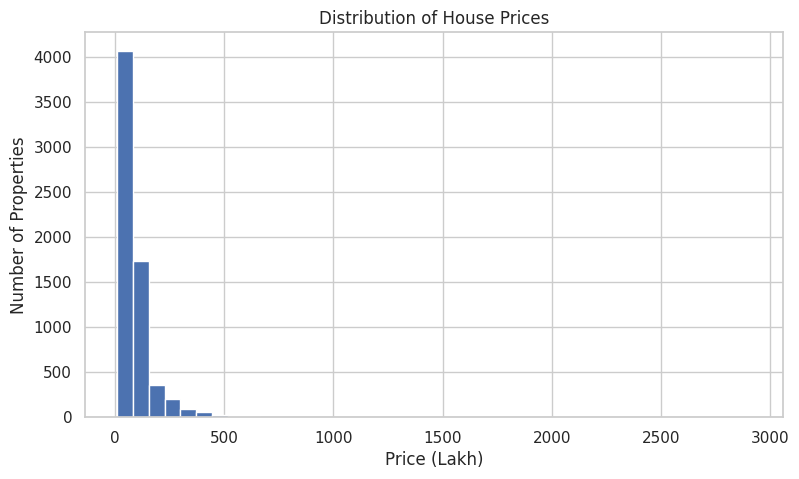

In [ ]:
# EDA 1 — House Price Distribution
plt.figure(figsize=(9,5))
plt.hist(df["price"], bins=40)
plt.title("Distribution of House Prices")
plt.xlabel("Price (Lakh)")
plt.ylabel("Number of Properties")
plt.show()

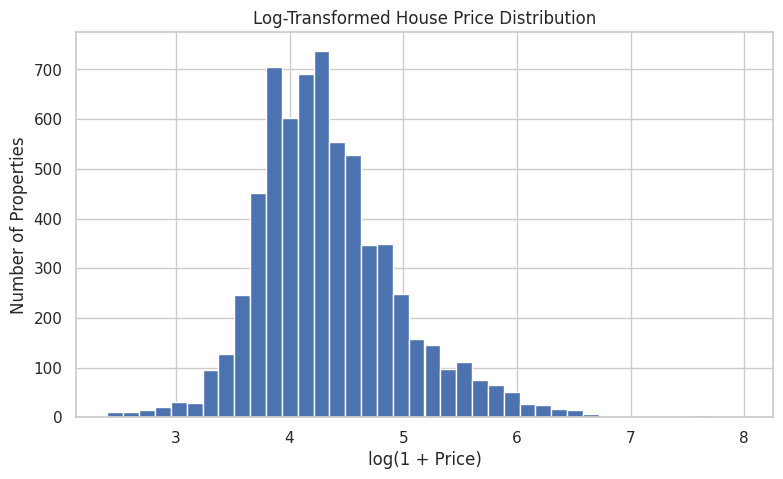

In [ ]:
# EDA 2 — Log Price Distribution
plt.figure(figsize=(9,5))
plt.hist(np.log1p(df["price"]), bins=40)
plt.title("Log-Transformed House Price Distribution")
plt.xlabel("log(1 + Price)")
plt.ylabel("Number of Properties")
plt.show()

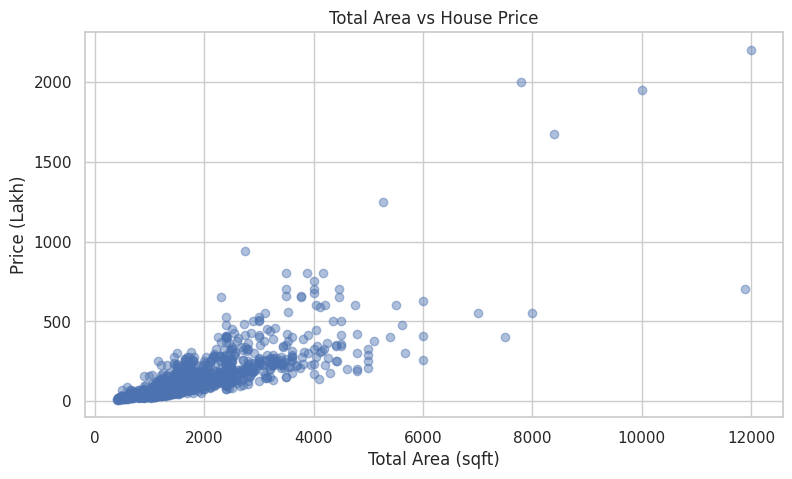

In [ ]:
# EDA 3 — Total Area vs Price
sample = df.sample(min(3000, len(df)), random_state=RANDOM_STATE)
plt.figure(figsize=(9,5))
plt.scatter(sample["total_sqft"], sample["price"], alpha=0.45)
plt.title("Total Area vs House Price")
plt.xlabel("Total Area (sqft)")
plt.ylabel("Price (Lakh)")
plt.show()

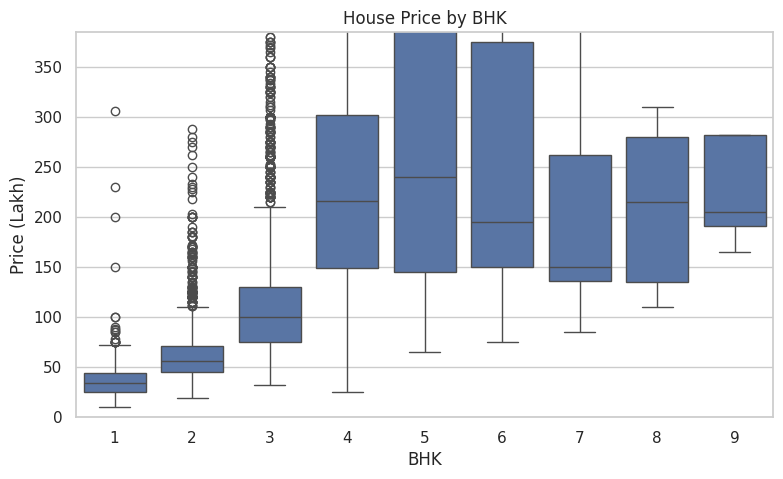

In [ ]:
# EDA 4 — BHK vs Price
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x="bhk", y="price")
plt.ylim(0, df["price"].quantile(0.98))
plt.title("House Price by BHK")
plt.xlabel("BHK")
plt.ylabel("Price (Lakh)")
plt.show()

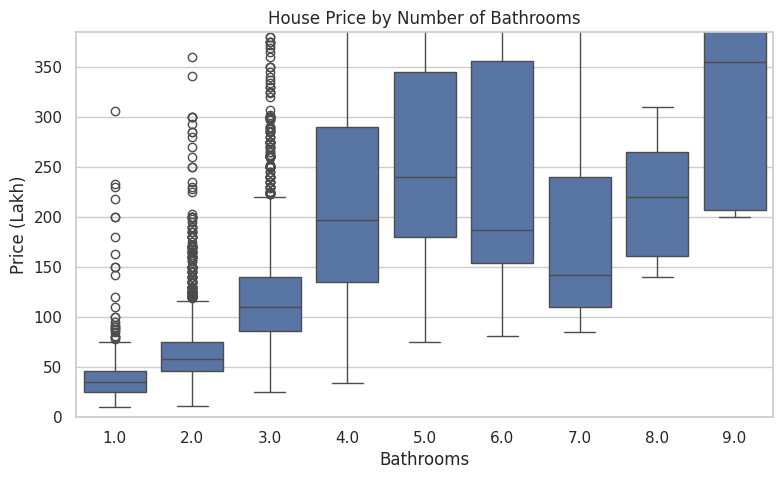

In [ ]:
# EDA 5 — Bathrooms vs Price
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x="bath", y="price")
plt.ylim(0, df["price"].quantile(0.98))
plt.title("House Price by Number of Bathrooms")
plt.xlabel("Bathrooms")
plt.ylabel("Price (Lakh)")
plt.show()

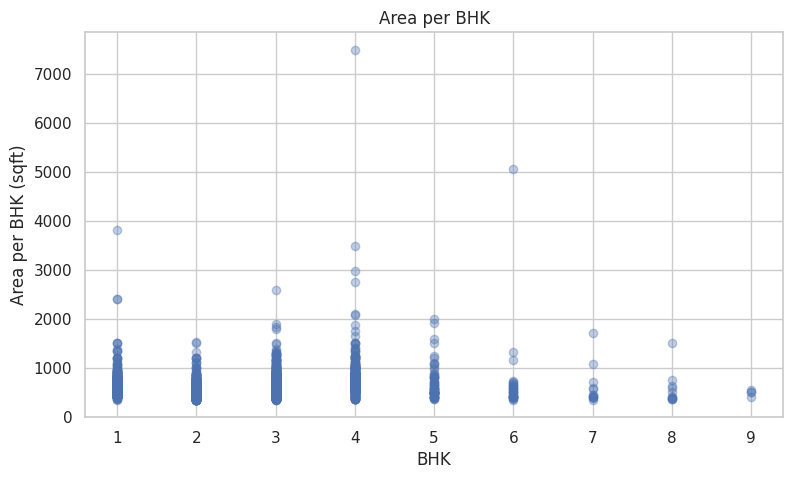

In [ ]:
# EDA 6 — Area per BHK
eda = df.copy()
eda["area_per_bhk"] = eda["total_sqft"] / eda["bhk"]
plt.figure(figsize=(9,5))
plt.scatter(eda["bhk"], eda["area_per_bhk"], alpha=0.35)
plt.title("Area per BHK")
plt.xlabel("BHK")
plt.ylabel("Area per BHK (sqft)")
plt.show()

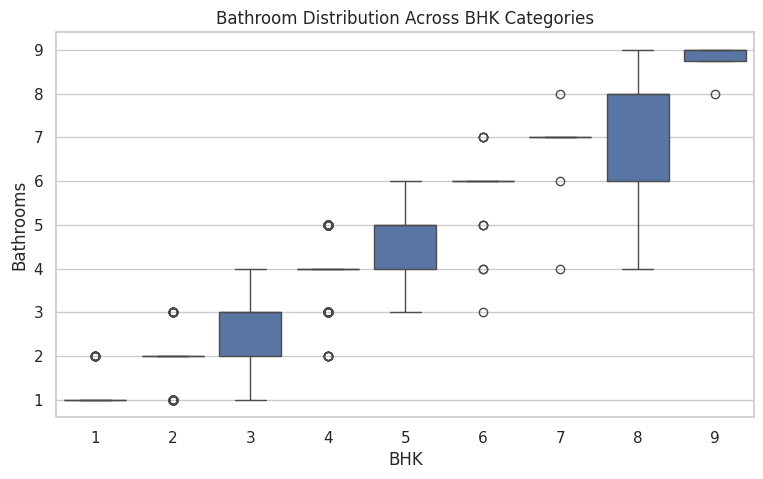

In [ ]:
# EDA 7 — Bathrooms by BHK
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x="bhk", y="bath")
plt.title("Bathroom Distribution Across BHK Categories")
plt.xlabel("BHK")
plt.ylabel("Bathrooms")
plt.show()

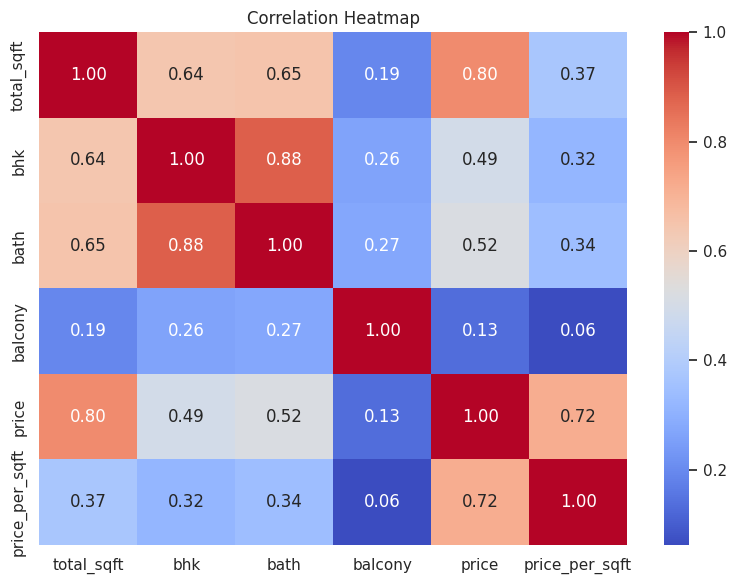

In [ ]:
# EDA 8 — Correlation Heatmap
corr = df[["total_sqft","bhk","bath","balcony","price","price_per_sqft"]].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

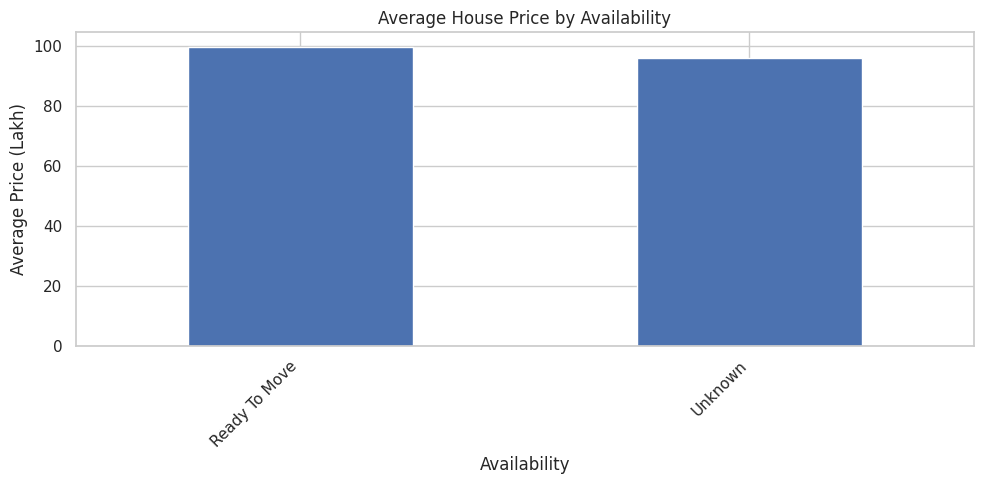

In [ ]:
# EDA 9 — Availability vs Average Price
availability_price = df.groupby("availability")["price"].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
availability_price.plot(kind="bar")
plt.title("Average House Price by Availability")
plt.xlabel("Availability")
plt.ylabel("Average Price (Lakh)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

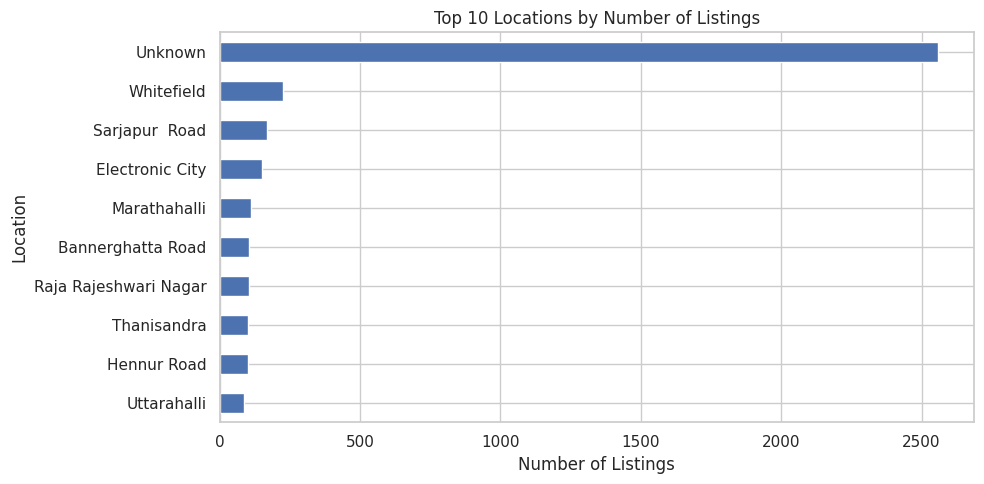

In [ ]:
# EDA 10 — Top Locations by Listing Count
top_locations = df["location"].value_counts().head(10)
plt.figure(figsize=(10,5))
top_locations.sort_values().plot(kind="barh")
plt.title("Top 10 Locations by Number of Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

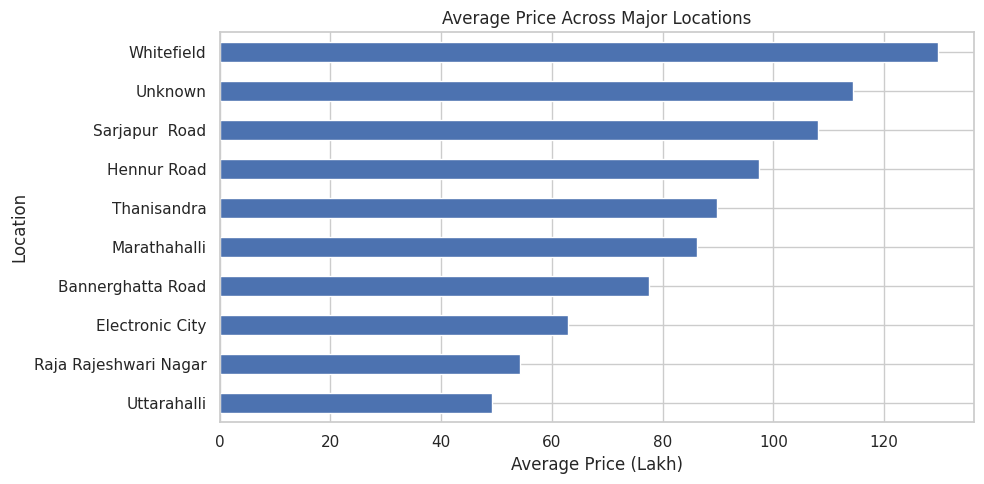

In [ ]:
# EDA 11 — Average Price in Top Locations
top_loc_names = df["location"].value_counts().head(10).index
avg_loc_price = df[df["location"].isin(top_loc_names)].groupby("location")["price"].mean().sort_values()
plt.figure(figsize=(10,5))
avg_loc_price.plot(kind="barh")
plt.title("Average Price Across Major Locations")
plt.xlabel("Average Price (Lakh)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

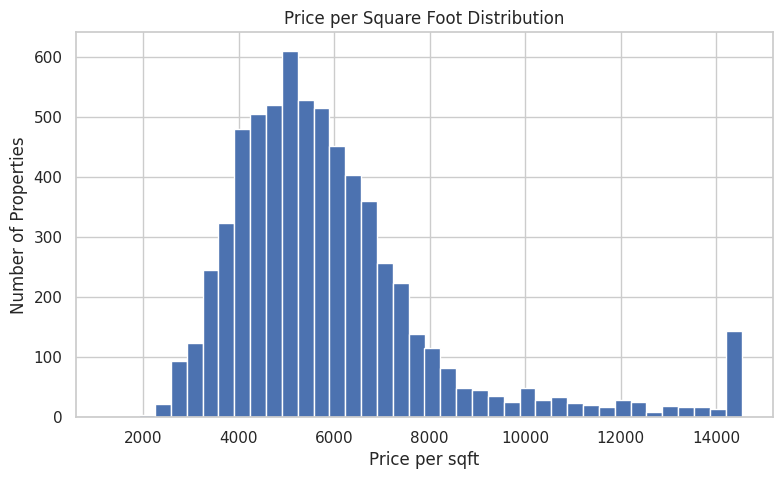

In [ ]:
# EDA 12 — Price per Square Foot
plt.figure(figsize=(9,5))
plt.hist(df["price_per_sqft"].clip(upper=df["price_per_sqft"].quantile(0.98)), bins=40)
plt.title("Price per Square Foot Distribution")
plt.xlabel("Price per sqft")
plt.ylabel("Number of Properties")
plt.show()

## 8. Feature Engineering and Preprocessing

Two useful numerical features are created:
- `area_per_bhk` — approximate space available per bedroom.
- `bath_per_bhk` — bathroom-to-bedroom ratio.

The target-derived `price_per_sqft` is excluded from modelling to prevent leakage.

In [ ]:
# 8. Feature Engineering

df["area_per_bhk"] = df["total_sqft"] / df["bhk"]
df["bath_per_bhk"] = df["bath"] / df["bhk"]

features = [
    "area_type", "availability", "location",
    "total_sqft", "bhk", "bath", "balcony",
    "area_per_bhk", "bath_per_bhk"
]

X = df[features]
y = df["price"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 5281
Testing rows: 1321


## 9. Model Training and Evaluation

In [ ]:
# 9. Train Three Regression Models

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=12, min_samples_leaf=3, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    rmse = mean_squared_error(y_test, pred) ** 0.5
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    results.append([name, rmse, mae, r2])
    fitted_models[name] = pipe

results_df = pd.DataFrame(
    results, columns=["Model", "RMSE", "MAE", "R2"]
).sort_values("RMSE")

display(results_df)

,Model,RMSE,MAE,R2
0,Linear Regression,62.349163,27.194311,0.700810
2,Random Forest,69.022397,24.509426,0.633338
1,Decision Tree,82.305780,26.908003,0.478629


<Figure size 1000x600 with 0 Axes>

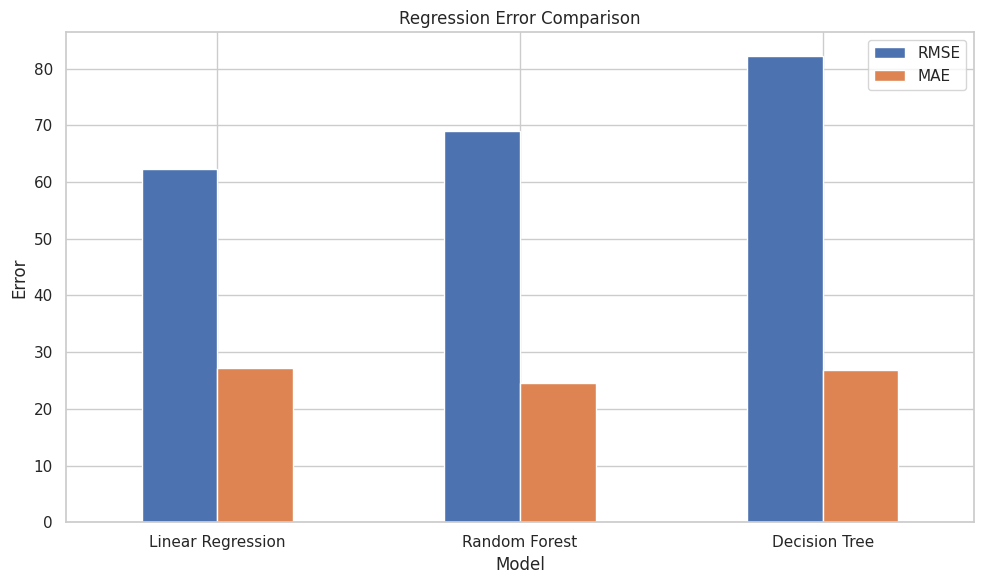

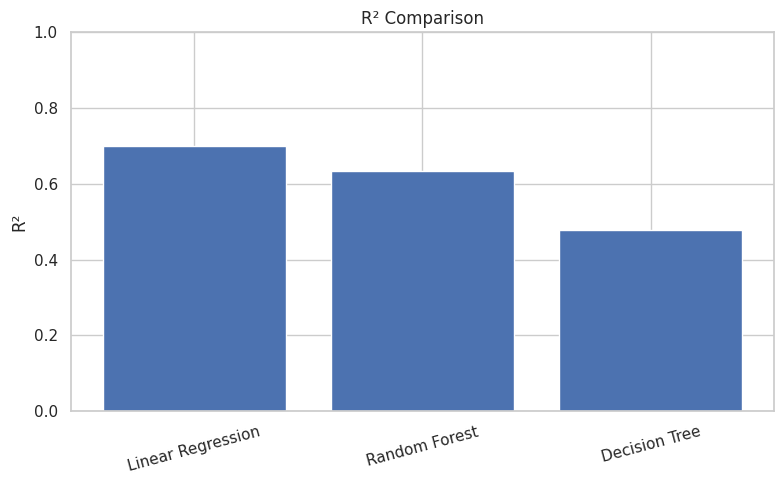

In [ ]:
# 10. Model Comparison

plt.figure(figsize=(10,6))
results_df.set_index("Model")[["RMSE","MAE"]].plot(kind="bar", figsize=(10,6))
plt.title("Regression Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["R2"])
plt.ylim(0,1)
plt.title("R² Comparison")
plt.ylabel("R²")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

,Feature,Importance
3,total_sqft,0.743037
5,bath,0.169924
2,location,0.087215
4,bhk,0.079332
7,area_per_bhk,0.034453


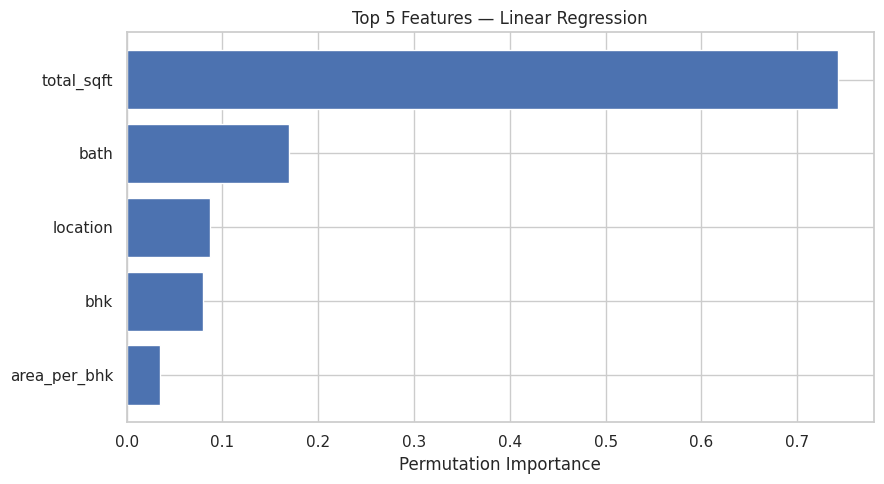

In [ ]:
# 11. Top 5 Important Features

best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]

perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="r2"
)

importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

display(importance.head(5))

plt.figure(figsize=(9,5))
top5 = importance.head(5).sort_values("Importance")
plt.barh(top5["Feature"], top5["Importance"])
plt.title(f"Top 5 Features — {best_name}")
plt.xlabel("Permutation Importance")
plt.tight_layout()
plt.show()

## 10. Business Interpretation and Conclusion

The selected model is the model with the lowest RMSE on the held-out test set. Lower RMSE/MAE indicates smaller prediction errors, while higher R² indicates that more variation in house prices is explained.

For a real-estate business, the model can support:
- preliminary property valuation,
- price benchmarking across locations,
- identifying high-value property characteristics,
- assisting buyers and sellers with data-driven estimates.

The model should be used as decision support rather than as the sole basis for property pricing.